# 05 – Controlled Experiments, Error Analysis and Comparison
**DS5007 NLP · Assignment 2 · Extractive QA on SQuAD 1.1**

| Experiment | Question | Design (one factor varied, everything else fixed) |
|---|---|---|
| **C** Input sequence length | How do accuracy, time and memory depend on `max_length`? | A3 (DistilBERT + windows) **trained and evaluated** at 128 / 256 / 384 tokens, stride = L/3, batch 16, lr 5e-5, 2 epochs |
| **D** Context truncation | What is lost when the context is cut? | (i) full context within the input limit (A2 at 384), (ii) truncated context (first window only) at 128 / 256 / 384, (iii) sliding windows at the same lengths – same weights in (ii)/(iii); plus paragraphs shortened to 25–75% of their length |
| **B** Training-data size | How much labelled data is needed? | A1 and A3 trained on 10 / 25 / 50 / 100% of the training questions (nested, seeded subsets), identical recipes |
| **A** Architecture | scratch vs pretrained vs windows | summary of notebooks 02–04 (section A) |
| **E** Error analysis | Where does the best model fail? | numbers, names, dates, multi-word answers, long paragraphs, truncation, ambiguity |

All runs use the shared `eqa_lib` pipeline (tokenizer, labels, span heads, loss, training loop, post-processing, metrics) and are evaluated on the **full validation set (10,570 questions)**. Every training run is cached (`results/logs/history_<run>.json`, checkpoints in `models/experiments/`), so re-running the notebook replays the saved logs instead of retraining. To save wall-clock time, the data-size runs of Experiment B were executed in parallel processes with the identical function calls (`scripts/run_a1_data_size.py`, `scripts/run_a3_data_size.py`) while this notebook trained the Experiment C models; they are reloaded here and their logs replayed.

In [1]:
# Environment: on Google Colab, mount Drive and work inside the uploaded project folder; locally nothing to do.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EQA_Assignment"      # <- path of the uploaded project folder
    os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "datasets", "gradio"])
sys.path.insert(0, os.path.abspath(".."))                     # make eqa_lib.py (project root) importable

import eqa_lib as eqa          # imported first: it initialises OpenSSL before torch/pyarrow (Windows workaround)
import json, time, re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
ENV = eqa.setup()

import gc

python         : 3.14.6
torch          : 2.14.1+cu126
transformers   : 5.19.0
numpy          : 2.4.6
pandas         : 3.0.3
device         : cuda
gpu            : NVIDIA GeForce RTX 4050 Laptop GPU
gpu_memory_gb  : 6.0
cuda           : 12.6
amp_dtype      : torch.bfloat16
seed           : 42
quick_run      : False
force_retrain  : False
project_root   : C:\Users\kiran\NLP Assignment 2\EQA_Assignment


In [2]:
A3_RC = dict(arch="pretrained", encoder="distilbert-base-uncased", input_strategy="sliding_window",
             max_length=384, doc_stride=128, lr=5e-5, batch_size=16, epochs=2, warmup_ratio=0.1, weight_decay=0.01,
             max_grad_norm=1.0, evals_per_epoch=1, patience=2, train_fraction=1.0)
A1_RC = dict(arch="scratch", scratch=dict(d_model=256, n_heads=4, n_layers=4, d_ff=1024, max_len=512, dropout=0.1),
             input_strategy="sliding_window", max_length=384, doc_stride=128, lr=5e-4, batch_size=32, epochs=10,
             warmup_ratio=0.1, weight_decay=0.01, max_grad_norm=1.0, evals_per_epoch=1, patience=2, train_fraction=1.0)
SEQ_SETTINGS = [(128, 42), (256, 85), (384, 128)]      # (max_length, doc_stride = max_length // 3)
FRACTIONS = [0.10, 0.25, 0.50]
SHORTEN = [0.25, 0.50, 0.75, 1.00]
EXP_DIR = eqa.PATHS.models / "experiments"
if eqa.QUICK_RUN:
    A3_RC["epochs"], A1_RC["epochs"] = 1, 2
    SEQ_SETTINGS, FRACTIONS = [(128, 42), (384, 128)], [0.5]

def is_cached(run, model_dir=None, save_ckpt=True):
    model_dir = model_dir or eqa.PATHS.models / run
    return (not eqa.FORCE_RETRAIN and (eqa.PATHS.logs / f"history_{run}.json").exists()
            and (not save_ckpt or (model_dir / "best_model.pt").exists()))

train_raw, val_df, _ = eqa.load_squad()
train_df, _ = eqa.clean_training_data(train_raw)
tokenizer = eqa.get_tokenizer()
val_eda = eqa.add_eda_columns(val_df, tokenizer)
print(f"{len(train_df):,} training / {len(val_df):,} validation questions")

Loaded from datasets.load_dataset('rajpurkar/squad'): 87,599 training / 10,570 validation examples


87,599 training / 10,570 validation questions


## C. Effect of the input sequence length
A3 is trained **and** evaluated with `max_length` ∈ {128, 256, 384} (stride = L/3 → 42 / 85 / 128 tokens of overlap). The 384-token model is the A3 model of notebook 04. Hyper-parameters, data, number of epochs and batch size are identical, so only the input length changes. For every length we record accuracy, training time, peak training memory, number of training/validation windows and inference time. Each model is also evaluated with **truncation** (first window only), which feeds Experiment D.

In [3]:
seq_path, perq_path = eqa.PATHS.results / "exp_C_sequence_length.csv", eqa.PATHS.results / "exp_D_per_question.csv"
if seq_path.exists() and perq_path.exists() and not eqa.FORCE_RETRAIN:
    print("[cache] loading Experiment C/D evaluation results")
    seq_df, perq = pd.read_csv(seq_path), pd.read_csv(perq_path)
    for L, stride in SEQ_SETTINGS:      # replay the training logs of the runs
        run = "distilbert_sliding_window" if L == 384 else f"A3_L{L}"
        print("\n".join(json.loads((eqa.PATHS.logs / f"history_{run}.json").read_text())["log_lines"][-3:]))
else:
    seq_rows, perq_parts = [], []
    for L, stride in SEQ_SETTINGS:
        run = "distilbert_sliding_window" if L == 384 else f"A3_L{L}"
        mdir = eqa.PATHS.models / run if L == 384 else EXP_DIR / run
        va_f, va_s = eqa.prepare_features(val_df, tokenizer, L, stride, sliding_window=True, keep_offsets=True)
        tr_f = None if is_cached(run, mdir) else eqa.prepare_features(train_df, tokenizer, L, stride, sliding_window=True)[0]
        rc = dict(A3_RC, max_length=L, doc_stride=stride)
        model, hist = eqa.train_model(run, rc, tr_f, va_f, val_df, model_dir=mdir)
        del tr_f; gc.collect()
        ev_w = eqa.evaluate_model(model, va_f, val_df)
        va_t = eqa.first_windows(va_f)
        ev_t = eqa.evaluate_model(model, va_t, val_df)
        if L != 384:
            eqa.log_experiment(eqa.experiment_row(run, f"Exp C: A3 windows, max_length {L}", hist, ev_w, "sliding_window", L, stride))
        seq_rows.append({"max_length": L, "doc_stride": stride, "train_windows": hist["n_train_features"],
                         "epochs": hist["epochs_run"], "train_min": hist["pure_train_time_min"],
                         "train_min_per_epoch": hist["pure_train_time_min"] / hist["epochs_run"],
                         "peak_train_mem_GB": hist["peak_gpu_mem_gb"], "val_windows": len(va_f["input_ids"]),
                         "windows_inference_s": ev_w["forward_seconds"], "windows_EM": ev_w["exact_match"], "windows_F1": ev_w["f1"],
                         "trunc_inputs": len(va_t["input_ids"]), "trunc_inference_s": ev_t["forward_seconds"],
                         "trunc_answer_reachable_pct": 100 * np.mean([s > 0 for s in va_t["start_positions"]]),
                         "trunc_EM": ev_t["exact_match"], "trunc_F1": ev_t["f1"]})
        for mode, ev in (("windows", ev_w), ("truncation", ev_t)):
            perq_parts.append(ev["details"][["id", "prediction", "em", "f1", "window", "confidence"]].assign(max_length=L, mode=mode))
        print(f"L={L}: windows EM {ev_w['exact_match']:.2f} / F1 {ev_w['f1']:.2f} | truncation EM {ev_t['exact_match']:.2f} / F1 {ev_t['f1']:.2f}")
        del model; gc.collect(); torch.cuda.empty_cache()
    seq_df, perq = pd.DataFrame(seq_rows), pd.concat(perq_parts, ignore_index=True)
    seq_df.to_csv(seq_path, index=False); perq.to_csv(perq_path, index=False)
display(seq_df.round(2))

[cache] loading Experiment C/D evaluation results
[A3_L128] epoch 2/2 step 11633/11647 | train loss 0.5207 | lr 3.34e-08 |  69.0 min, ETA   0.0 min
[A3_L128] >>> eval @ epoch 2.00: train loss 0.5660 | val loss 0.8359 | EM 77.60 | F1 85.23  (new best)
[A3_L128] done: 69.4 min (68.0 min training, 1.4 min validation) | best F1 85.23 | peak GPU memory 1.28 GB
[A3_L256] epoch 2/2 step  6036/6044 | train loss 0.7541 | lr 3.68e-08 |  70.5 min, ETA   0.0 min
[A3_L256] >>> eval @ epoch 2.00: train loss 0.8001 | val loss 1.0822 | EM 77.56 | F1 85.74  (new best)
[A3_L256] done: 70.9 min (70.1 min training, 0.8 min validation) | best F1 85.74 | peak GPU memory 1.67 GB
[distilbert_sliding_window] epoch 2/2 step  5527/5533 | train loss 0.7821 | lr 3.01e-08 |  19.4 min, ETA   0.0 min
[distilbert_sliding_window] >>> eval @ epoch 2.00: train loss 0.8107 | val loss 1.1030 | EM 77.69 | F1 85.67  (new best)
[distilbert_sliding_window] done: 19.7 min (18.5 min training, 1.2 min validation) | best F1 85.67 

,max_length,doc_stride,train_windows,epochs,train_min,train_min_per_epoch,peak_train_mem_GB,val_windows,windows_inference_s,windows_EM,windows_F1,trunc_inputs,trunc_inference_s,trunc_answer_reachable_pct,trunc_EM,trunc_F1
0,128,42,186347,2.0,68.05,34.02,1.28,23473,22.46,77.60,85.23,10570,11.23,79.73,64.14,71.54
1,256,85,96693,2.0,70.12,35.06,1.67,11945,17.78,77.56,85.74,10570,15.78,98.50,76.65,84.82
2,384,128,88524,2.0,18.51,9.25,2.08,10784,16.71,77.69,85.67,10570,16.56,99.68,77.51,85.46


### C.1 Training throughput measured in isolation
The measured wall-clock times of the 128- and 256-token runs are **not comparable**. The data-size runs of Experiment B were executed concurrently with the 128-token run to save time (GPU sharing). In addition, the laptop went into sleep mode for ≈46 minutes during the 256-token run, and that pause is included in its elapsed time. Peak memory is measured per process and is unaffected, and so is accuracy. For a fair time comparison we therefore benchmark the training throughput of every input length **alone on the GPU**. Each benchmark uses 10 warm-up steps and then 150 timed optimisation steps on batches drawn from the real length-grouped sampler, with batch size 16. Multiplying the time per step by the number of steps per epoch gives a comparable estimate of the training time per epoch.

In [4]:
bench_path = eqa.PATHS.results / "exp_C_throughput_benchmark.csv"
if bench_path.exists() and not eqa.FORCE_RETRAIN:
    bench = pd.read_csv(bench_path)
else:
    rows = []
    for L, stride in SEQ_SETTINGS:
        tr_f, _ = eqa.prepare_features(train_df, tokenizer, L, stride, sliding_window=True)
        sampler = eqa.LengthGroupedBatchSampler([len(x) for x in tr_f["input_ids"]], A3_RC["batch_size"])
        batches = list(iter(sampler))
        pick = np.random.default_rng(eqa.SEED).choice(len(batches), 160, replace=False)
        ds = eqa.QAFeatureDataset(tr_f)
        eqa.set_seed()
        model = eqa.build_model(A3_RC).to(eqa.DEVICE).train()
        opt = torch.optim.AdamW(model.parameters(), lr=A3_RC["lr"])
        torch.cuda.reset_peak_memory_stats()
        for k, b in enumerate(pick):
            if k == 10:
                torch.cuda.synchronize(); t0 = time.time()
            batch = eqa.collate([ds[i] for i in batches[b]]); batch.pop("feature_idx")
            batch = {kk: v.to(eqa.DEVICE) for kk, v in batch.items()}
            with eqa.autocast_ctx():
                loss = model(**batch)["loss"]
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        sps = (time.time() - t0) / 150
        rows.append({"max_length": L, "train_windows": len(tr_f["input_ids"]), "steps_per_epoch": len(batches),
                     "sec_per_step": sps, "est_min_per_epoch_isolated": sps * len(batches) / 60,
                     "peak_mem_GB_benchmark": torch.cuda.max_memory_allocated() / 1024 ** 3})
        print(f"L={L}: {len(batches):,} steps/epoch x {sps:.3f} s/step = {sps * len(batches) / 60:.1f} min/epoch (isolated)")
        del model, opt, tr_f, ds; gc.collect(); torch.cuda.empty_cache()
    bench = pd.DataFrame(rows)
    bench.to_csv(bench_path, index=False)
seq_df = seq_df.drop(columns=[c for c in bench.columns if c in seq_df.columns and c != "max_length"]).merge(bench, on="max_length")
seq_df["measured_min_per_epoch"] = seq_df["train_min_per_epoch"]
display(seq_df[["max_length", "doc_stride", "train_windows", "steps_per_epoch", "sec_per_step", "est_min_per_epoch_isolated",
                "measured_min_per_epoch", "peak_train_mem_GB", "val_windows", "windows_inference_s", "windows_EM", "windows_F1"]].round(3))
print("measured_min_per_epoch of the 128/256-token runs is inflated (GPU sharing / system sleep); use est_min_per_epoch_isolated for comparisons.")

L=128: 11,647 steps/epoch x 0.089 s/step = 17.2 min/epoch (isolated)


L=256: 6,044 steps/epoch x 0.111 s/step = 11.2 min/epoch (isolated)


L=384: 5,533 steps/epoch x 0.119 s/step = 11.0 min/epoch (isolated)


,max_length,doc_stride,train_windows,steps_per_epoch,sec_per_step,est_min_per_epoch_isolated,measured_min_per_epoch,peak_train_mem_GB,val_windows,windows_inference_s,windows_EM,windows_F1
0,128,42,186347,11647,0.089,17.240,34.023,1.282,23473,22.456,77.597,85.225
1,256,85,96693,6044,0.111,11.217,35.059,1.668,11945,17.783,77.559,85.739
2,384,128,88524,5533,0.119,10.970,9.254,2.078,10784,16.709,77.692,85.673


measured_min_per_epoch of the 128/256-token runs is inflated (GPU sharing / system sleep); use est_min_per_epoch_isolated for comparisons.


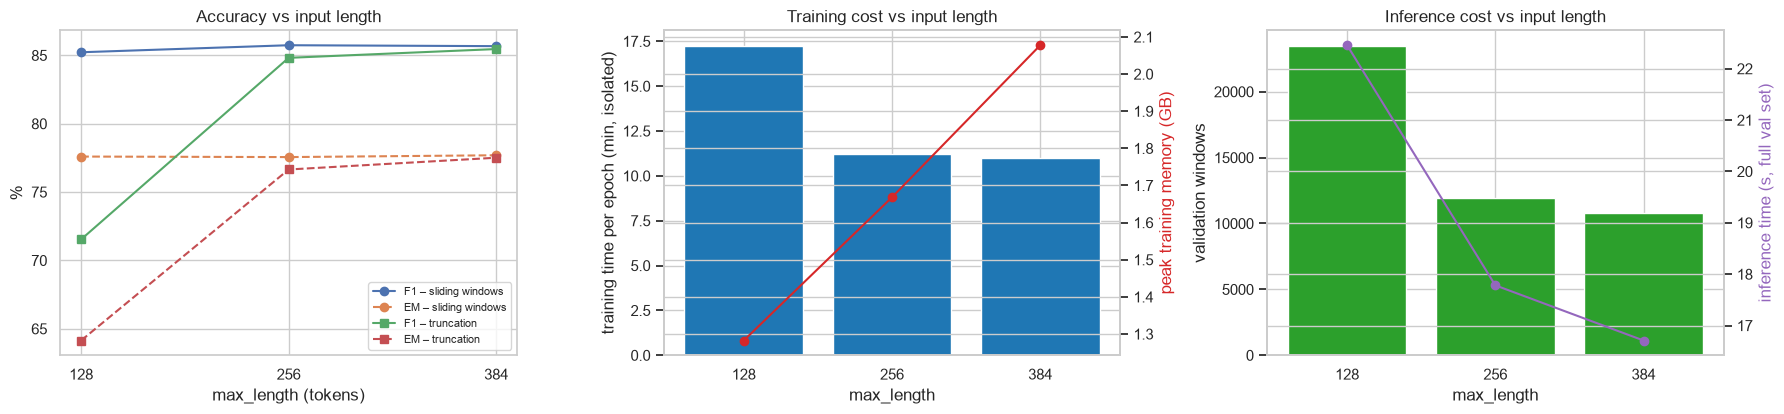

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
x = seq_df["max_length"]
axes[0].plot(x, seq_df["windows_F1"], "o-", label="F1 – sliding windows"); axes[0].plot(x, seq_df["windows_EM"], "o--", label="EM – sliding windows")
axes[0].plot(x, seq_df["trunc_F1"], "s-", label="F1 – truncation"); axes[0].plot(x, seq_df["trunc_EM"], "s--", label="EM – truncation")
axes[0].set_xticks(x); axes[0].set_xlabel("max_length (tokens)"); axes[0].set_ylabel("%"); axes[0].set_title("Accuracy vs input length"); axes[0].legend(fontsize=8)
axes[1].bar(x.astype(str), seq_df["est_min_per_epoch_isolated"], color="#1f77b4"); axes[1].set_ylabel("training time per epoch (min, isolated)")
ax2 = axes[1].twinx(); ax2.plot(x.astype(str), seq_df["peak_train_mem_GB"], "o-", color="#d62728"); ax2.set_ylabel("peak training memory (GB)", color="#d62728")
axes[1].set_xlabel("max_length"); axes[1].set_title("Training cost vs input length")
axes[2].bar(x.astype(str), seq_df["val_windows"], color="#2ca02c"); axes[2].set_ylabel("validation windows")
ax3 = axes[2].twinx(); ax3.plot(x.astype(str), seq_df["windows_inference_s"], "o-", color="#9467bd"); ax3.set_ylabel("inference time (s, full val set)", color="#9467bd")
axes[2].set_xlabel("max_length"); axes[2].set_title("Inference cost vs input length")
eqa.savefig("05_expC_sequence_length")

**Interpretation (Experiment C).** * **With sliding windows, accuracy is almost independent of the input length:** F1 85.23 (128 tokens), 85.74 (256) and 85.67 (384). The model still sees every token of the context, and SQuAD answers depend mostly on local evidence (usually the same sentence), so 42–128 tokens of overlap give enough context around each answer.
* **Memory falls with the length:** peak training memory is 1.28 GB at 128 tokens vs 2.08 GB at 384 (38% less), because activations and attention maps grow with the sequence length (attention quadratically).
* **Time does not fall:** shorter windows need many more inputs (11,647 vs 5,533 optimisation steps per epoch), and every token in the overlaps is processed twice. Measured in isolation, an epoch takes 17.2 min at 128 tokens (0.089 s/step), 11.2 min at 256 and 11.0 min at 384 (0.119 s/step). Inference over the validation set needs 23,473 windows and 22.5 s at 128 tokens vs 10,784 windows and 16.7 s at 384.
* **Conclusion:** 256–384 tokens is the sweet spot on this GPU. Short windows only pay off when memory is the binding constraint, and only together with sliding windows (see Experiment D).

## D. Effect of context truncation
### D.1 Full context vs. truncated context vs. sliding windows
* **Full context within the input limit:** A2 (trained and evaluated with truncation at 384 tokens; 99.7% of answers fit).
* **Truncated context:** each A3-L model sees only its first window (the first ≈L tokens).
* **Sliding windows:** the same A3-L model sees all windows.

"Answer reachable" is the share of questions whose gold answer lies completely inside the visible input, i.e. the upper bound for that setting.

In [6]:
logs = pd.read_csv(eqa.PATHS.results / "experiment_logs.csv")
a2 = logs[logs["run"] == "distilbert_baseline"]
rows = []
if len(a2):
    rows.append({"setting": "A2: full context within the 384-token limit (truncation-trained)", "max_length": 384,
                 "answer reachable (%)": 99.68, "EM": float(a2["EM"].iloc[0]), "F1": float(a2["F1"].iloc[0])})
for _, r in seq_df.iterrows():
    rows.append({"setting": f"A3-{int(r.max_length)}: truncated to the first window", "max_length": int(r.max_length),
                 "answer reachable (%)": r.trunc_answer_reachable_pct, "EM": r.trunc_EM, "F1": r.trunc_F1})
    rows.append({"setting": f"A3-{int(r.max_length)}: sliding windows (stride {int(r.doc_stride)})", "max_length": int(r.max_length),
                 "answer reachable (%)": 100.0, "EM": r.windows_EM, "F1": r.windows_F1})
expD = pd.DataFrame(rows)
expD.to_csv(eqa.PATHS.results / "exp_D_truncation.csv", index=False)
display(expD.round(2))

,setting,max_length,answer reachable (%),EM,F1
0,A2: full context within the 384-token limit (truncation-trained),384,99.68,78.06,85.89
1,A3-128: truncated to the first window,128,79.73,64.14,71.54
2,A3-128: sliding windows (stride 42),128,100.00,77.60,85.23
3,A3-256: truncated to the first window,256,98.50,76.65,84.82
4,A3-256: sliding windows (stride 85),256,100.00,77.56,85.74
5,A3-384: truncated to the first window,384,99.68,77.51,85.46
6,A3-384: sliding windows (stride 128),384,100.00,77.69,85.67


### D.2 Which questions become difficult when the relevant span is removed?
We locate every gold answer by the token index of its start inside the context and compare truncation and windows per position bucket. We also check which question types lose most at 128 tokens.

setting,questions,truncation L=128,truncation L=256,truncation L=384,windows L=128,windows L=256,windows L=384
answer_position,,,,,,,
0-60,5739,87.2,87.0,86.3,85.6,86.8,86.3
60-120,3194,75.9,84.7,85.4,85.1,84.5,85.4
120-180,1166,9.0,83.9,83.7,84.1,83.2,83.7
180-250,347,6.2,78.4,86.0,85.0,87.5,86.1
250-350,89,7.8,13.7,83.4,83.7,87.4,82.9
350+,35,8.6,13.9,13.8,78.5,81.3,83.0


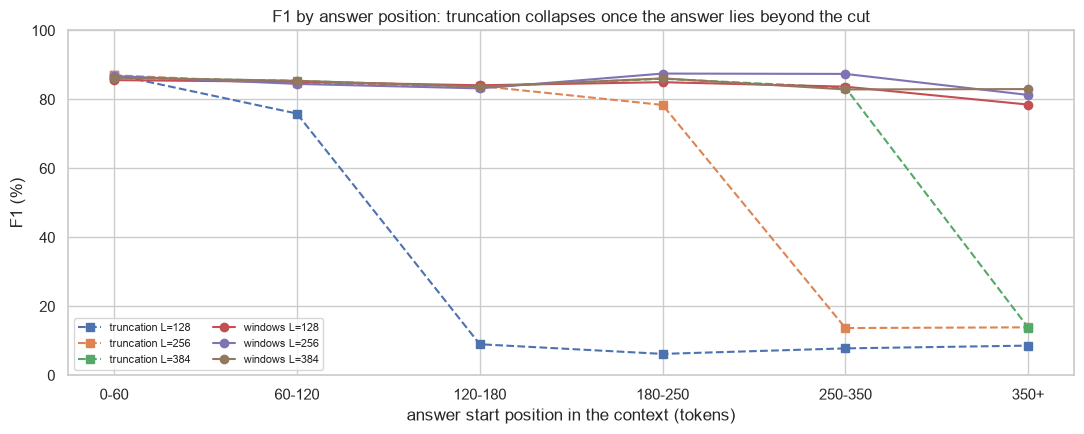

At max_length = 128:


,questions,answer_cut_off_pct,F1_truncation,F1_windows,F1 loss from truncation
qtype,,,,,
how much,154,21.4,70.3,87.2,16.8
how many,642,17.4,73.0,89.1,16.1
which,698,21.2,71.4,87.1,15.7
how,432,22.0,61.4,76.8,15.4
other,94,26.6,51.8,67.0,15.3
when,713,17.1,78.1,92.2,14.1
what,6021,18.8,70.8,84.5,13.7
who,1185,15.5,76.6,88.3,11.7
why,155,21.9,63.3,73.9,10.6


1203 questions are answered exactly with windows but completely wrong with truncation at 128 tokens, e.g.:
  Q: What did Smedley Butler call US foreign Policy?
     gold: ['a "racket"', 'racket'] | truncation: 'Monroe Doctrine' | windows: 'racket'
  Q: This person proposed explanations for the origins of earthquakes and the formation of mountains, what was his name?
     gold: ['Ibn Sina'] | truncation: 'Fielding H. Garrison' | windows: 'Ibn Sina'
  Q: What is another name for the Tabula Rogeriana?
     gold: ['Kitab Rudjdjar'] | truncation: 'Sicily' | windows: 'Kitab Rudjdjar'
  Q: In what country can most of the Amazon rainforest be found?
     gold: ['Brazil'] | truncation: 'South America' | windows: 'Brazil'


In [7]:
pos = val_eda[["id", "qtype", "answer_start_token_in_context", "question_tokens", "pair_tokens", "answer_words"]].copy()
pos["answer_position"] = pd.cut(pos["answer_start_token_in_context"], [-1, 60, 120, 180, 250, 350, 10_000],
                                labels=["0-60", "60-120", "120-180", "180-250", "250-350", "350+"])
pq = perq.merge(pos, on="id")
pq["setting"] = pq["mode"] + " L=" + pq["max_length"].astype(str)
by_pos = pq.groupby(["answer_position", "setting"], observed=True)["f1"].mean().mul(100).unstack().round(1)
by_pos.insert(0, "questions", pos["answer_position"].value_counts().reindex(by_pos.index).values)
display(by_pos)
fig, ax = plt.subplots(figsize=(11, 4.5))
for col in [c for c in by_pos.columns if c != "questions"]:
    ax.plot(by_pos.index.astype(str), by_pos[col], "s--" if col.startswith("truncation") else "o-", label=col)
ax.set_xlabel("answer start position in the context (tokens)"); ax.set_ylabel("F1 (%)"); ax.set_ylim(0, 100)
ax.set_title("F1 by answer position: truncation collapses once the answer lies beyond the cut"); ax.legend(fontsize=8, ncol=2)
eqa.savefig("05_expD_f1_by_answer_position")

if (pq["max_length"] == 128).any():
    q128 = pq[pq["max_length"] == 128].pivot_table(index=["id", "qtype"], columns="mode", values="f1").reset_index()
    q128["cut_off"] = q128["id"].map(pos.set_index("id")["answer_start_token_in_context"]
                                     > 128 - 3 - pos.set_index("id")["question_tokens"])
    by_qtype = q128.groupby("qtype").agg(questions=("id", "size"), answer_cut_off_pct=("cut_off", "mean"),
                                         F1_truncation=("truncation", "mean"), F1_windows=("windows", "mean"))
    by_qtype[["answer_cut_off_pct", "F1_truncation", "F1_windows"]] *= 100
    by_qtype["F1 loss from truncation"] = by_qtype["F1_windows"] - by_qtype["F1_truncation"]
    print("At max_length = 128:")
    display(by_qtype.sort_values("F1 loss from truncation", ascending=False).round(1))
    lost = q128[q128["cut_off"] & (q128["windows"] == 1) & (q128["truncation"] == 0)].merge(val_df[["id", "question", "answer_texts"]], on="id")
    preds = perq[perq["max_length"] == 128].pivot_table(index="id", columns="mode", values="prediction", aggfunc="first")
    print(f"{len(lost)} questions are answered exactly with windows but completely wrong with truncation at 128 tokens, e.g.:")
    for r in lost.sample(min(4, len(lost)), random_state=eqa.SEED).itertuples():
        print(f"  Q: {r.question}\n     gold: {list(dict.fromkeys(r.answer_texts))} | truncation: {preds.loc[r.id, 'truncation']!r} | "
              f"windows: {preds.loc[r.id, 'windows']!r}")

### D.3 Shortened paragraphs
Here we shorten the paragraphs themselves, independent of the model's input limit: each validation context is cut to its first 25 / 50 / 75 / 100% of characters (at a word boundary) and answered by the A3-384 model. When the gold answer is removed, the question can only be answered "correctly" if an alternative reference answer survives. We report accuracy separately for questions whose answer survived and those whose answer was removed.

,paragraph kept (%),mean context words,answers kept (%),EM all,F1 all,F1 | answer kept,F1 | answer removed
0,25,30.50,31.65,28.08,34.10,89.79,8.31
1,50,61.63,57.15,47.57,54.52,87.63,10.37
2,75,92.55,78.43,62.76,70.50,86.48,12.40
3,100,123.95,100.00,77.69,85.67,85.67,NaN


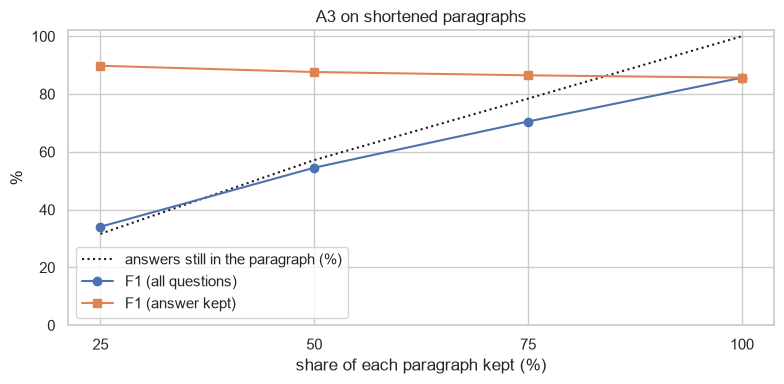

In [8]:
short_path = eqa.PATHS.results / "exp_D_shortened_paragraphs.csv"
if short_path.exists() and not eqa.FORCE_RETRAIN:
    short_df = pd.read_csv(short_path)
else:
    a3 = eqa.load_qa_model(eqa.PATHS.models / "distilbert_sliding_window")
    rows = []
    for frac in SHORTEN:
        sdf = val_df.copy()
        cuts = []
        for c in sdf["context"]:
            cut = int(len(c) * frac)
            sp = c.rfind(" ", 0, cut) if frac < 1 else len(c)
            cuts.append(sp if sp > 0 else cut)
        sdf["context"] = [c[:k] for c, k in zip(sdf["context"], cuts)]
        kept = np.array([s[0] + len(t[0]) <= k for s, t, k in zip(val_df["answer_starts"], val_df["answer_texts"], cuts)])
        f, _ = eqa.prepare_features(sdf, tokenizer, 384, 128, sliding_window=True, keep_offsets=True)
        ev = eqa.evaluate_model(a3, f, sdf)
        em, f1 = ev["details"]["em"].to_numpy(), ev["details"]["f1"].to_numpy()
        rows.append({"paragraph kept (%)": int(frac * 100), "mean context words": float(sdf["context"].str.split().str.len().mean()),
                     "answers kept (%)": 100 * kept.mean(), "EM all": 100 * em.mean(), "F1 all": 100 * f1.mean(),
                     "F1 | answer kept": 100 * f1[kept].mean(),
                     "F1 | answer removed": 100 * f1[~kept].mean() if (~kept).any() else float("nan")})
        print(f"{frac:.0%}: answers kept {100 * kept.mean():.1f}% | F1 {100 * f1.mean():.2f}")
    short_df = pd.DataFrame(rows)
    short_df.to_csv(short_path, index=False)
    del a3; gc.collect(); torch.cuda.empty_cache()
display(short_df.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(short_df["paragraph kept (%)"], short_df["answers kept (%)"], "k:", label="answers still in the paragraph (%)")
ax.plot(short_df["paragraph kept (%)"], short_df["F1 all"], "o-", label="F1 (all questions)")
ax.plot(short_df["paragraph kept (%)"], short_df["F1 | answer kept"], "s-", label="F1 (answer kept)")
ax.set_xlabel("share of each paragraph kept (%)"); ax.set_ylabel("%"); ax.set_ylim(0, 102); ax.legend()
ax.set_title("A3 on shortened paragraphs"); ax.set_xticks(short_df["paragraph kept (%)"])
eqa.savefig("05_expD_shortened_paragraphs")

**Interpretation (Experiment D).** * **Truncation costs exactly as much as it hides.** At 384 tokens, 99.7% of answers stay visible and truncation loses only 0.2 F1. At 256 tokens, 98.5% stay visible (−0.9 F1). At 128 tokens only 79.7% remain, and F1 drops from 85.23 to 71.54 (−13.7). The A2 model, trained with truncation at 384 tokens, is as good as A3 here (it sees the full context for 99.7% of questions).
* **Which questions become difficult?** Exactly those whose answer lies after the cut. Per answer position, truncated models are as accurate as windows while the answer is visible (≈85–87 F1). Beyond the cut, F1 collapses to ≈6–14, and the few remaining points come only from alternative reference answers or accidental overlap. At 128 tokens, 1,203 questions are answered exactly with windows but completely wrong with truncation. Typically the model then confidently returns a plausible distractor from the visible part (*"South America"* instead of *"Brazil"*, *"Monroe Doctrine"* instead of *"racket"*). All question types lose 10–17 F1 at 128 tokens (*how much/how many* most, *where/why* least), so the loss is positional rather than tied to a question type.
* **Shortened paragraphs.** Keeping only the first 25/50/75% of each paragraph leaves 31.6/57.2/78.4% of the answers, and F1 falls to 34.1/54.5/70.5, tracking the share of surviving answers. Questions whose answer survives are answered *better* (F1 89.8 at 25% vs 85.7 with full paragraphs), because shorter contexts contain fewer distractors. Questions whose answer was removed score only ≈8–12 F1: a SQuAD 1.1 model never abstains, it always returns some span.
* **Overlapping windows remove this failure mode** at the cost of extra inputs, so they should be used whenever contexts can exceed the input limit.

## B. Effect of the training-data size
Both A1 (scratch) and A3 (DistilBERT + windows) are trained on **10%, 25% and 50%** of the training *questions* (all windows of a selected question are kept). Subsets are drawn with a fixed seed from one permutation, so they are **nested** (10% ⊂ 25% ⊂ 50%). The 100% points are the main runs of notebooks 02 and 04. The recipes are unchanged: A3 trains for 2 epochs, A1 for up to 10 epochs with early stopping.

*Compute note:* these runs were executed concurrently with the 128-token run of Experiment C, so their wall-clock times (`train_min`) are inflated by GPU sharing and are **not** comparable. Training compute is therefore reported as the exact number of **optimisation steps**. For A3 the cost per step equals that of the full run (≈0.10 s, isolated), so training time scales linearly with the amount of data. Accuracy and memory are unaffected.

In [9]:
need_feats = any(not is_cached(f"{a}_frac{int(round(f * 100))}", save_ckpt=False) for a in ("A3", "A1") for f in FRACTIONS)
va_384, _ = eqa.prepare_features(val_df, tokenizer, 384, 128, sliding_window=True, keep_offsets=True)
tr_384 = eqa.prepare_features(train_df, tokenizer, 384, 128, sliding_window=True)[0] if need_feats else None
size_rows = []
for approach, rc, full_run in (("A3 DistilBERT + windows", A3_RC, "distilbert_sliding_window"), ("A1 Transformer from scratch", A1_RC, "transformer_scratch")):
    for frac in FRACTIONS:
        run = f"{approach[:2]}_frac{int(round(frac * 100))}"
        _, h = eqa.train_model(run, dict(rc, train_fraction=frac), tr_384, va_384, val_df, save_ckpt=False)
        size_rows.append({"approach": approach, "run": run, "train_fraction": frac, "train_questions": h["n_train_examples"],
                          "train_inputs": h["n_train_features"], "epochs_run": h["epochs_run"], "best_epoch": h["best"]["epoch"],
                          "train_min": h["pure_train_time_min"], "optimisation_steps": int(round(h["steps_per_epoch"] * h["epochs_run"])), "EM": h["best"]["exact_match"], "F1": h["best"]["f1"]})
    hp = eqa.PATHS.logs / f"history_{full_run}.json"
    if not hp.exists():
        continue
    h = json.loads(hp.read_text())
    size_rows.append({"approach": approach, "run": full_run, "train_fraction": 1.0, "train_questions": h["n_train_examples"],
                      "train_inputs": h["n_train_features"], "epochs_run": h["epochs_run"], "best_epoch": h["best"]["epoch"],
                      "train_min": h["pure_train_time_min"], "optimisation_steps": int(round(h["steps_per_epoch"] * h["epochs_run"])), "EM": h["best"]["exact_match"], "F1": h["best"]["f1"]})
size_df = pd.DataFrame(size_rows)
size_df.to_csv(eqa.PATHS.results / "exp_B_data_size.csv", index=False)
display(size_df.round(2))
del tr_384
_ = gc.collect()

[cache] 'A3_frac10' already trained – replaying its saved log (set EQA_FORCE_RETRAIN=1 to retrain).
=== A3_frac10: 66.36M params | 8,760 questions -> 8,849 inputs | 2 epochs x 554 steps (batch 16, lr 5e-05) ===
[A3_frac10] epoch 1/2 step    55/554 | train loss 4.8451 | lr 2.50e-05 |   0.3 min, ETA   5.1 min
[A3_frac10] epoch 1/2 step   110/554 | train loss 3.8912 | lr 5.00e-05 |   0.5 min, ETA   4.7 min
[A3_frac10] epoch 1/2 step   165/554 | train loss 3.0806 | lr 4.72e-05 |   0.8 min, ETA   4.4 min
[A3_frac10] epoch 1/2 step   220/554 | train loss 2.5873 | lr 4.45e-05 |   1.0 min, ETA   4.2 min
[A3_frac10] epoch 1/2 step   275/554 | train loss 2.2146 | lr 4.17e-05 |   1.3 min, ETA   3.9 min
[A3_frac10] epoch 1/2 step   330/554 | train loss 2.0456 | lr 3.90e-05 |   1.5 min, ETA   3.6 min
[A3_frac10] epoch 1/2 step   385/554 | train loss 1.9569 | lr 3.62e-05 |   1.8 min, ETA   3.4 min
[A3_frac10] epoch 1/2 step   440/554 | train loss 1.8306 | lr 3.35e-05 |   2.0 min, ETA   3.1 min
[A3_f

,approach,run,train_fraction,train_questions,train_inputs,epochs_run,best_epoch,train_min,optimisation_steps,EM,F1
0,A3 DistilBERT + windows,A3_frac10,0.10,8760,8849,2.0,2.0,5.06,1108,63.80,74.40
1,A3 DistilBERT + windows,A3_frac25,0.25,21900,22112,2.0,2.0,12.39,2764,70.55,80.10
2,A3 DistilBERT + windows,A3_frac50,0.50,43800,44234,2.0,2.0,24.95,5530,74.86,83.57
3,A3 DistilBERT + windows,distilbert_sliding_window,1.00,87599,88524,2.0,2.0,18.51,11066,77.69,85.67
4,A1 Transformer from scratch,A1_frac10,0.10,8760,8849,4.0,2.0,0.70,1108,2.58,9.70
5,A1 Transformer from scratch,A1_frac25,0.25,21900,22112,7.0,5.0,4.33,4837,6.78,14.32
6,A1 Transformer from scratch,A1_frac50,0.50,43800,44234,7.0,5.0,14.57,9681,8.20,16.55
7,A1 Transformer from scratch,transformer_scratch,1.00,87599,88524,7.0,5.0,12.25,19369,10.53,20.09


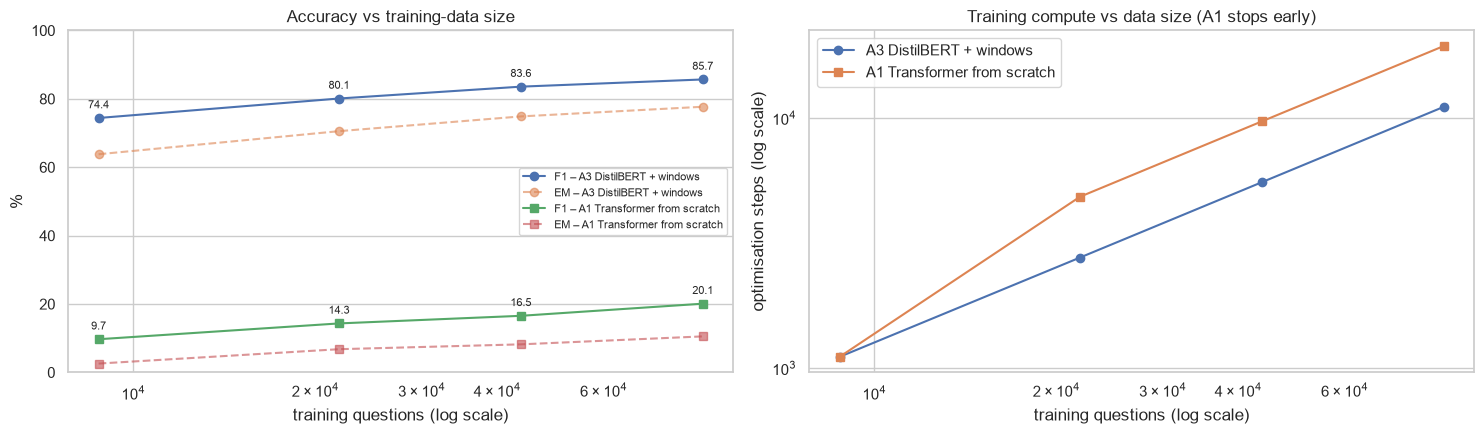

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for approach, mk in (("A3 DistilBERT + windows", "o"), ("A1 Transformer from scratch", "s")):
    s = size_df[size_df["approach"] == approach].sort_values("train_questions")
    axes[0].plot(s["train_questions"], s["F1"], mk + "-", label=f"F1 – {approach}")
    axes[0].plot(s["train_questions"], s["EM"], mk + "--", alpha=0.6, label=f"EM – {approach}")
    for _, r in s.iterrows():
        axes[0].annotate(f"{r['F1']:.1f}", (r["train_questions"], r["F1"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    axes[1].plot(s["train_questions"], s["optimisation_steps"], mk + "-", label=approach)
axes[0].set_xscale("log"); axes[0].set_xlabel("training questions (log scale)"); axes[0].set_ylabel("%"); axes[0].set_ylim(0, 100)
axes[0].set_title("Accuracy vs training-data size"); axes[0].legend(fontsize=8)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("training questions (log scale)"); axes[1].set_ylabel("optimisation steps (log scale)")
axes[1].set_title("Training compute vs data size (A1 stops early)"); axes[1].legend()
eqa.savefig("05_expB_data_size")

**Interpretation (Experiment B).** * **Pretraining is worth far more than data.** A3 trained on only 10% of the questions (8,760) reaches F1 74.40, i.e. 3.7× the F1 of A1 trained on all 87,599 questions (20.09).
* **Diminishing returns for the pretrained model.** A3 gains +5.7 F1 from 10% to 25%, +3.5 from 25% to 50% and +2.1 from 50% to 100%. Performance grows roughly logarithmically with the data and approaches DistilBERT's ceiling.
* **A1 is data-starved.** It scores 9.70 → 14.32 → 16.55 → 20.09: steady gains of ≈3–4 F1 per doubling, but from a very low level, and it overfits faster on small subsets (best epoch 2 with 10% of the data).
* **Compute scales linearly with data:** 1,108 → 11,066 optimisation steps for A3 (≈0.10 s/step). A3 with 25% of the data (2,764 steps) beats A1 trained on everything (19,369 steps) by 60 F1 points.

## A. Comparison of the three approaches (architecture, accuracy, cost)
All three main models were trained on the full training set and evaluated on the full validation set with identical post-processing and metrics (notebooks 02–04). The values below are read from `results/experiment_logs.csv` and the training histories. The extra BERT-base row is an **optional reference**, not one of the three required approaches: a 12-layer encoder fine-tuned with the same code, whose run was stopped after epoch 1 of a 2-epoch schedule to free the GPU. It shows where a larger pretrained encoder would land.

In [11]:
MAIN = {"transformer_scratch": "A1 Transformer from scratch", "distilbert_baseline": "A2 DistilBERT (truncation)",
        "distilbert_sliding_window": "A3 DistilBERT + sliding windows"}
logs = pd.read_csv(eqa.PATHS.results / "experiment_logs.csv")
A = logs[logs["run"].isin(MAIN)].set_index("run").loc[[r for r in MAIN if r in set(logs["run"])]]
hists = {r: json.loads((eqa.PATHS.logs / f"history_{r}.json").read_text()) for r in A.index}
cmpA = pd.DataFrame({
    "approach": [MAIN[r] for r in A.index], "params (M)": A["params_M"], "checkpoint (MB)": A["model_size_MB"],
    "epochs run": A["epochs_run"], "train time (min)": A["pure_train_time_min"], "min / epoch": A["train_min_per_epoch"],
    "peak train GPU (GB)": A["peak_train_gpu_mem_GB"], "val inputs": A["val_inputs"],
    "inference full val (s)": A["inference_s_full_val"], "inference (inputs/s)": A["inference_inputs_per_s"],
    "best train loss": A["best_train_loss"], "best val loss": A["best_val_loss"], "EM": A["EM"], "F1": A["F1"]}).reset_index(drop=True)
ref_dir = eqa.PATHS.models / "extra_bert_base_reference"
if ref_dir.exists():
    ref = json.loads((ref_dir / "run_config.json").read_text())["best_eval"]
    cmpA.loc[len(cmpA)] = {"approach": "(reference) BERT-base + windows, 1 of 2 epochs", "params (M)": 109.48,
                           "checkpoint (MB)": (ref_dir / "best_model.pt").stat().st_size / 1e6, "epochs run": ref["epoch"],
                           "best train loss": ref["train_loss"], "best val loss": ref["val_loss"],
                           "EM": ref["exact_match"], "F1": ref["f1"]}
cmpA.to_csv(eqa.PATHS.results / "exp_A_architecture_comparison.csv", index=False)
display(cmpA.round(2))

,approach,params (M),checkpoint (MB),epochs run,train time (min),min / epoch,peak train GPU (GB),val inputs,inference full val (s),inference (inputs/s),best train loss,best val loss,EM,F1
0,A1 Transformer from scratch,11.11,44.45,7.0,12.25,1.75,1.32,10784.0,4.83,2232.59,3.16,4.07,10.53,20.09
1,A2 DistilBERT (truncation),66.36,265.50,2.0,18.52,9.26,2.33,10570.0,14.21,743.89,0.81,1.09,78.06,85.89
2,A3 DistilBERT + sliding windows,66.36,265.50,2.0,18.51,9.25,2.08,10784.0,13.78,782.49,0.81,1.10,77.69,85.67
3,"(reference) BERT-base + windows, 1 of 2 epochs",109.48,438.02,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1.10,1.05,79.97,87.35


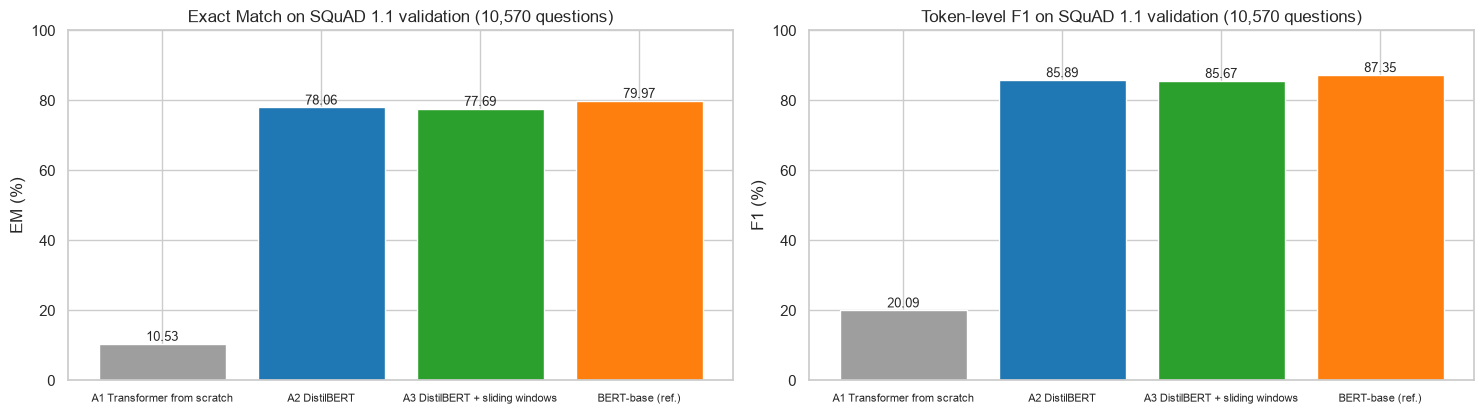

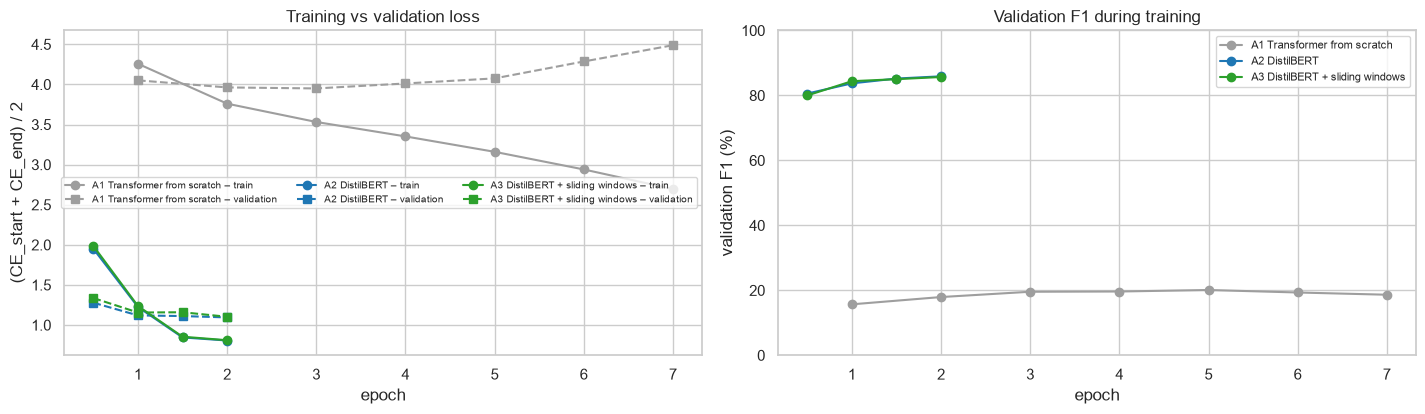

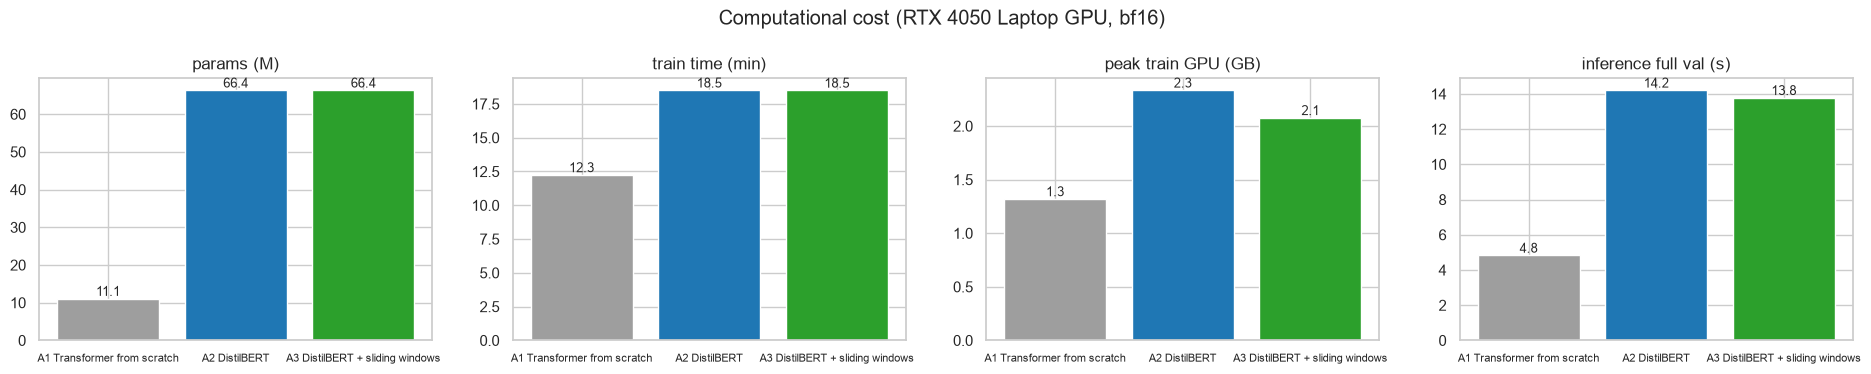

In [12]:
colors = {"A1": "#9e9e9e", "A2": "#1f77b4", "A3": "#2ca02c", "(r": "#ff7f0e"}
short = lambda a: a.split(" (")[0] if not a.startswith("(") else "BERT-base (ref.)"
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for ax, metric in zip(axes, ("EM", "F1")):
    bars = ax.bar([short(a) for a in cmpA["approach"]], cmpA[metric], color=[colors[a[:2]] for a in cmpA["approach"]])
    ax.bar_label(bars, fmt="%.2f", fontsize=9); ax.set_ylim(0, 100); ax.set_ylabel(f"{metric} (%)")
    ax.set_title(f"{'Exact Match' if metric == 'EM' else 'Token-level F1'} on SQuAD 1.1 validation (10,570 questions)")
    ax.tick_params(axis="x", labelsize=8)
eqa.savefig("05_expA_em_f1_comparison")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for r, h in hists.items():
    ev = pd.DataFrame(h["evals"]); c = colors[MAIN[r][:2]]
    axes[0].plot(ev["epoch"], ev["train_loss"], "o-", color=c, label=f"{short(MAIN[r])} – train")
    axes[0].plot(ev["epoch"], ev["val_loss"], "s--", color=c, label=f"{short(MAIN[r])} – validation")
    axes[1].plot(ev["epoch"], ev["f1"], "o-", color=c, label=short(MAIN[r]))
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("(CE_start + CE_end) / 2"); axes[0].set_title("Training vs validation loss"); axes[0].legend(fontsize=7, ncol=3)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation F1 (%)"); axes[1].set_ylim(0, 100); axes[1].set_title("Validation F1 during training"); axes[1].legend(fontsize=8)
eqa.savefig("05_expA_loss_curves_all")

core = cmpA[~cmpA["approach"].str.startswith("(")]
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, col in zip(axes, ["params (M)", "train time (min)", "peak train GPU (GB)", "inference full val (s)"]):
    bars = ax.bar([short(a) for a in core["approach"]], core[col], color=[colors[a[:2]] for a in core["approach"]])
    ax.bar_label(bars, fmt="%.1f", fontsize=9); ax.set_title(col); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Computational cost (RTX 4050 Laptop GPU, bf16)")
eqa.savefig("05_expA_compute_cost")

**Interpretation (Experiment A).** * **Pretraining dominates.** With identical data, heads, loss, training loop and metrics, A2/A3 (F1 ≈ 85.7–85.9) outperform A1 (F1 20.1) by ≈66 F1 points. A1 overfits after three epochs (validation loss 3.95 → 4.49 while training loss keeps falling) and learns answer-type shortcuts. DistilBERT's validation loss decreases monotonically, and half an epoch already gives F1 ≈ 80.
* **A2 vs A3.** They are statistically tied overall (bootstrap CI of the F1 difference [−0.66, +0.25]), because 98% of validation questions fit into one 384-token input. Windows matter only for long contexts: +10.7 F1 on the 183 long-context questions, and 14.9 → 83.6 F1 when the answer lies beyond the cut.
* **Cost.** A2 and A3 train equally fast (18.5 min, 9.3 min/epoch) with ≈2.1–2.3 GB peak memory. A1 is 1.5× faster to train, ≈3× faster at inference and 6× smaller (44 MB vs 265 MB), but its accuracy gap is far larger than its cost advantage. Windows add only ≈2% inference cost at 384 tokens.
* **Reference.** BERT-base (110M parameters) reaches F1 87.35 after a single epoch. A larger pretrained encoder would improve further at roughly 2× DistilBERT's cost.

## E. Error analysis
We analyse the predictions of **A3 (DistilBERT + sliding windows)**. It is statistically tied with A2 for the best overall score (notebook 04, paired bootstrap) and is the model we recommend, because it also handles long paragraphs. Truncation-specific errors are taken from **A2** and from the 128-token truncation setting of Experiment D. Categories are assigned with transparent rules on the first reference answer:
* **Answer type:** *Date* (a "when" question, or the answer contains a month, a year 1000–2099, a decade or "century"); *Number* (otherwise contains a digit or number word, or a "how many/much" question); *Name* (otherwise every content word is capitalised, i.e. a proper noun phrase); *Other*.
* **Answer length:** 1 word, 2–3, 4–6, 7+ words (multi-word answers).
* **Position:** relative position of the answer in its paragraph; *near the end of a long paragraph* = context ≥ 250 tokens and answer in the last quarter.
* **Ambiguity:** *unanimous* (all references identical after normalisation), *boundary disagreement* (different references that overlap, e.g. "Paramount Building" vs "the Paramount Building at 1501 Broadway"), *different answers* (at least two references share no word, so the question genuinely admits different answers).
* **Outcome:** exact (EM = 1) / partial (0 < F1 < 1) / wrong (F1 = 0). Errors are split into *too long*, *too short*, *boundary shift* and *wrong span*.

In [13]:
MONTHS = r"(january|february|march|april|may|june|july|august|september|october|november|december)"
DATE_RE = re.compile(rf"\b{MONTHS}\b|\b(1[0-9]{{3}}|20[0-9]{{2}})s?\b|\bcentur(y|ies)\b", re.I)
NUM_WORDS = set(("one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen "
                 "nineteen twenty thirty forty fifty sixty seventy eighty ninety hundred thousand million billion trillion dozen "
                 "half percent").split())
NAME_STOP = {"of", "the", "and", "de", "da", "von", "van", "du", "la", "le", "del", "for", "in", "on", "a", "an", "&"}

def answer_type(answer, question):
    qt = eqa.question_type(question)
    if qt == "when" or DATE_RE.search(answer):
        return "Date"
    if re.search(r"\d", answer) or any(w in NUM_WORDS for w in re.findall(r"[a-z]+", answer.lower())) or qt in ("how many", "how much"):
        return "Number"
    words = [w for w in re.findall(r"[A-Za-zÀ-ÿ][\w'\-\.]*", answer) if w.lower() not in NAME_STOP]
    return "Name" if words and all(w[0].isupper() for w in words) else "Other"

def length_bucket(n):
    return "1 word" if n == 1 else "2-3 words" if n <= 3 else "4-6 words" if n <= 6 else "7+ words"

def error_category(pred, golds):
    if eqa.metric_max_over_ground_truths(eqa.exact_match_score, pred, golds) == 1:
        return "correct"
    if eqa.metric_max_over_ground_truths(eqa.f1_score, pred, golds) == 0:
        return "wrong span (no overlap)"
    p = " " + eqa.normalize_answer(pred) + " "
    gs = [" " + eqa.normalize_answer(g) + " " for g in golds]
    if p.strip() and any(p in g for g in gs):
        return "too short (prediction inside reference)"
    if any(g.strip() and g in p for g in gs):
        return "too long (reference inside prediction)"
    return "boundary shift (partial overlap)"

ANALYSED = "distilbert_sliding_window"
det = pd.read_csv(eqa.PATHS.results / f"details_{ANALYSED}.csv", keep_default_na=False)
ea = val_eda.merge(det[["id", "prediction", "em", "f1", "confidence", "window"]], on="id")
ea["prediction"] = ea["prediction"].astype(str)
ea["answer_type"] = [answer_type(a[0], q) for a, q in zip(ea["answer_texts"], ea["question"])]
ea["answer_length"] = ea["answer_words"].map(length_bucket)
ea["multi_word"] = ea["answer_words"] >= 2
def ambiguity_level(refs):
    norm = list(dict.fromkeys(eqa.normalize_answer(t) for t in refs))
    if len(norm) == 1:
        return "unanimous"
    disjoint = any(eqa.f1_score(a, b) == 0 for i, a in enumerate(norm) for b in norm[i + 1:])
    return "different answers" if disjoint else "boundary disagreement"

ea["ambiguity"] = ea["answer_texts"].map(ambiguity_level)
ea["ambiguous"] = ea["ambiguity"] == "different answers"
ea["end_of_long_paragraph"] = (ea["context_tokens"] >= 250) & (ea["answer_rel_pos"] >= 0.75)
ea["outcome"] = np.where(ea["em"] == 1, "exact", np.where(ea["f1"] > 0, "partial", "wrong"))
ea["error_category"] = [error_category(p, g) for p, g in zip(ea["prediction"], ea["answer_texts"])]
print(f"Analysed model: {ANALYSED} | EM {100 * ea['em'].mean():.2f} | F1 {100 * ea['f1'].mean():.2f}")
print(ea["outcome"].value_counts(normalize=True).mul(100).round(2).to_string(), "\n")
print("Non-exact predictions by error category:")
print(ea.loc[ea["outcome"] != "exact", "error_category"].value_counts().to_string())

Analysed model: distilbert_sliding_window | EM 77.69 | F1 85.67
outcome
exact      77.69
partial    13.95
wrong       8.36 

Non-exact predictions by error category:
error_category
wrong span (no overlap)                    884
too long (reference inside prediction)     764
too short (prediction inside reference)    515
boundary shift (partial overlap)           195


--- by answer type (numbers, names, dates) ---


,n,EM,F1,mean_confidence
answer_type,,,,
Date,1178,88.62,92.49,0.76
Number,1499,78.45,87.09,0.64
Name,3296,84.28,88.77,0.70
Other,4597,69.92,81.25,0.51


--- by answer length (multi-word answers) ---


,n,EM,F1,mean_confidence
answer_length,,,,
1 word,3429,81.80,86.56,0.70
2-3 words,4575,79.87,86.62,0.63
4-6 words,1648,73.85,85.62,0.51
7+ words,918,58.39,77.72,0.39


--- by question type ---


,n,EM,F1,mean_confidence
qtype,,,,
what,6021,76.96,85.19,0.59
who,1185,83.29,87.74,0.73
when,713,89.76,92.70,0.76
which,698,82.38,87.71,0.65
how many,642,84.58,89.76,0.71
where,476,70.38,81.91,0.56
how,432,58.80,76.86,0.44
why,155,51.61,76.21,0.31
how much,154,75.97,85.19,0.60


--- by answer near the end of a long paragraph ---


,n,EM,F1,mean_confidence
end_of_long_paragraph,,,,
False,10414,77.78,85.70,0.62
True,156,71.79,84.13,0.56


--- by annotator agreement (ambiguity) ---


,n,EM,F1,mean_confidence
ambiguity,,,,
unanimous,5915,82.52,87.89,0.70
boundary disagreement,3526,73.65,84.55,0.52
different answers,1129,65.01,77.58,0.47


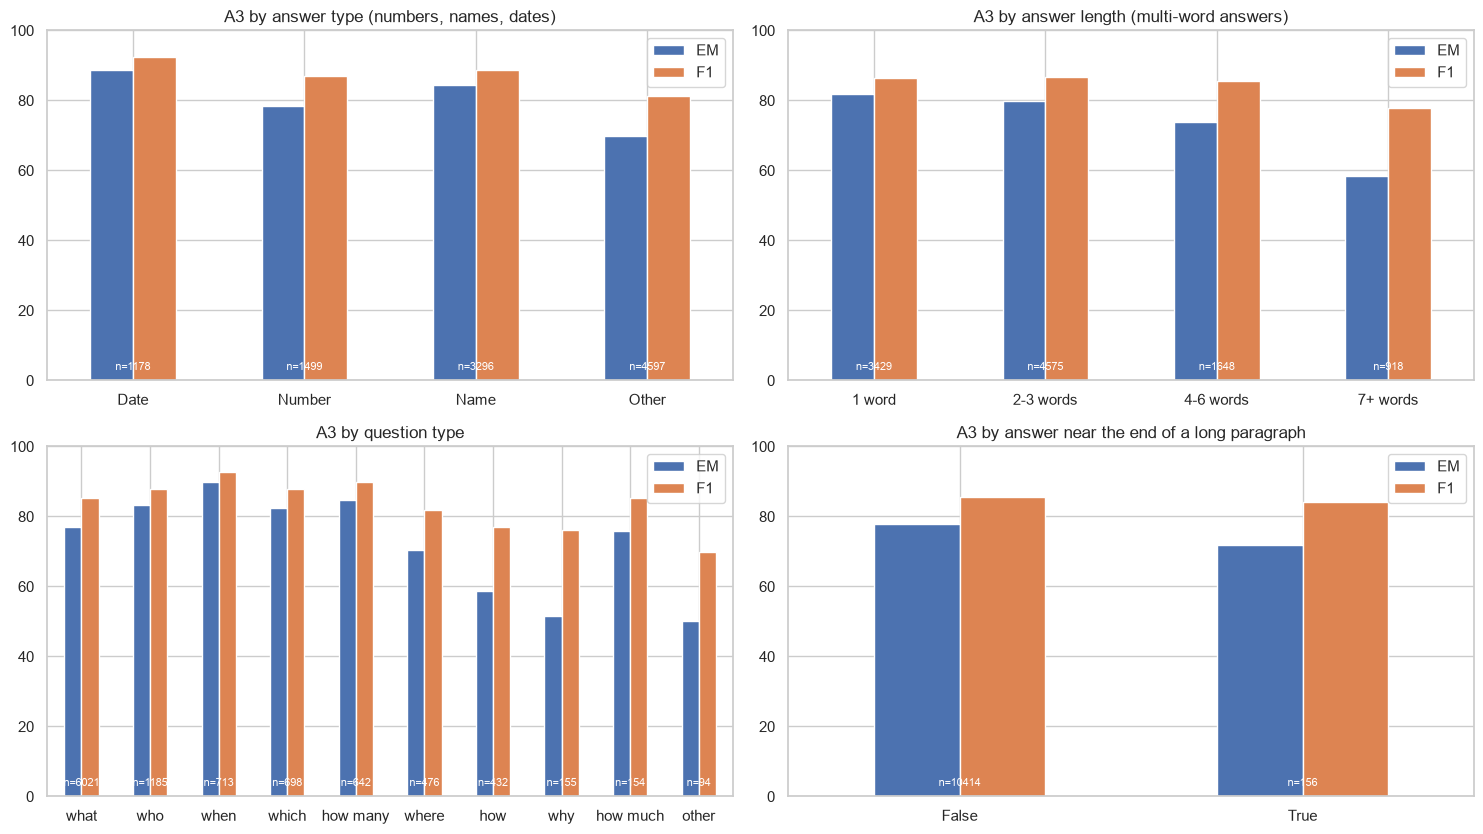

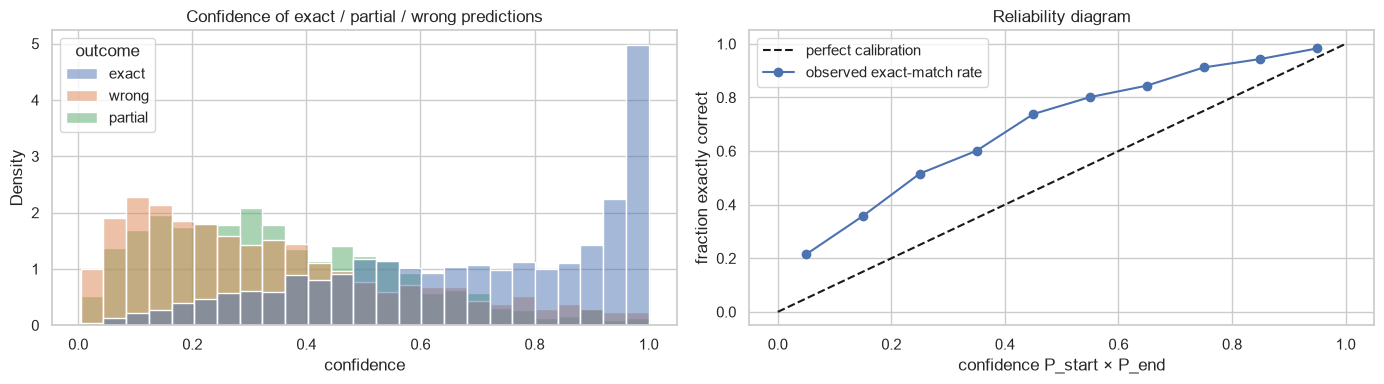

In [14]:
def breakdown(col, order=None):
    g = ea.groupby(col).agg(n=("id", "size"), EM=("em", "mean"), F1=("f1", "mean"), mean_confidence=("confidence", "mean"))
    g[["EM", "F1"]] *= 100
    return g.reindex([o for o in order if o in g.index]) if order else g.sort_values("n", ascending=False)

tables = {
    "answer type (numbers, names, dates)": breakdown("answer_type", ["Date", "Number", "Name", "Other"]),
    "answer length (multi-word answers)": breakdown("answer_length", ["1 word", "2-3 words", "4-6 words", "7+ words"]),
    "question type": breakdown("qtype"),
    "answer near the end of a long paragraph": breakdown("end_of_long_paragraph", [False, True]),
    "annotator agreement (ambiguity)": breakdown("ambiguity", ["unanimous", "boundary disagreement", "different answers"]),
}
for name, t in tables.items():
    print(f"--- by {name} ---"); display(t.round(2))
breakdown_all = pd.concat({k: v.reset_index().rename(columns={v.index.name: "group"}) for k, v in tables.items()}).reset_index(level=0).rename(columns={"level_0": "dimension"})
breakdown_all.to_csv(eqa.PATHS.results / "error_breakdown.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for ax, key in zip(axes.flat, list(tables)[:4]):
    t = tables[key]
    t[["EM", "F1"]].plot.bar(ax=ax, rot=0); ax.set_ylim(0, 100); ax.set_title(f"A3 by {key}"); ax.set_xlabel("")
    for i, n in enumerate(t["n"]):
        ax.text(i, 3, f"n={n}", ha="center", fontsize=8, color="white")
eqa.savefig("05_error_breakdowns")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=ea, x="confidence", hue="outcome", bins=25, stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Confidence of exact / partial / wrong predictions")
ea["conf_bin"] = pd.cut(ea["confidence"], np.linspace(0, 1, 11))
cal = ea.groupby("conf_bin", observed=True).agg(EM=("em", "mean"), n=("id", "size"))
axes[1].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[1].plot([b.mid for b in cal.index], cal["EM"], "o-", label="observed exact-match rate")
axes[1].set_xlabel("confidence P_start × P_end"); axes[1].set_ylabel("fraction exactly correct"); axes[1].legend(); axes[1].set_title("Reliability diagram")
eqa.savefig("05_error_confidence")

### E.1 Incorrect predictions with possible reasons
We draw a fixed-seed sample of **incorrect** predictions covering the categories required by the brief: numbers, dates, names, multi-word answers, answers near the end of long paragraphs, answers removed by truncation (A2), and ambiguous questions. For each we show the context (around the gold answer), question, reference answer(s), prediction, EM, F1 and a rule-based first diagnosis. A manual reading of the examples follows the table.

In [15]:
def diagnose(r):
    """Rule-based first diagnosis of an error (refined by hand in the discussion below)."""
    golds = list(dict.fromkeys(r["answer_texts"]))
    gold_type, pred_type = r["answer_type"], answer_type(r["prediction"], r["question"]) if r["prediction"] else "Other"
    if r.get("source", "") == "A2 truncation" and r.get("answer_cut", False):
        return "Answer lies beyond the 384-token truncation point: it is invisible to the model, which picks the best span in the visible part."
    if r.get("source", "") == "A3-128 truncation":
        return "Answer cut off by truncation at 128 tokens; the model answers from the first window only."
    cat = r["error_category"]
    if cat.startswith("too long"):
        return "Boundary error: the right answer plus extra words (modifier, apposition or second clause) beyond the reference span."
    if cat.startswith("too short"):
        return "Boundary error: only part of the reference span is returned (e.g. head noun without its modifier)."
    if cat.startswith("boundary"):
        return "Boundary shift: overlaps the reference but starts/ends at a different word."
    if gold_type in ("Number", "Date", "Name") and pred_type == gold_type:
        return f"Distractor of the same type: another {gold_type.lower()} from the paragraph matches the question's answer type but not its meaning."
    if r["ambiguous"]:
        return "Ambiguous question: the annotators themselves gave different (non-overlapping) answers; the prediction is yet another candidate."
    return "Wrong region: the question paraphrases the context or needs multi-sentence reasoning, and the lexical match points elsewhere."

def context_window(row, width=150):
    ctx, s = row["context"], row["answer_starts"][0]
    a, b = max(0, s - width), min(len(ctx), s + len(row["answer_texts"][0]) + width)
    return ("…" if a else "") + ctx[a:b].replace("\n", " ") + ("…" if b < len(ctx) else "")

wrong = ea[ea["em"] == 0].assign(source="A3")
picks = []
pick = lambda df, n: df.sample(min(n, len(df)), random_state=eqa.SEED)
picks += [pick(wrong[wrong["answer_type"] == t], 2) for t in ("Number", "Date", "Name")]
picks += [pick(wrong[(wrong["answer_type"] == "Other") & (wrong["answer_words"] >= 4)], 2)]
picks += [pick(wrong[wrong["end_of_long_paragraph"]], 2)]
taken = pd.concat(picks)["id"]
picks += [pick(wrong[wrong["ambiguous"] & ~wrong["id"].isin(taken)], 2)]
a2 = pd.read_csv(eqa.PATHS.results / "details_distilbert_baseline.csv", keep_default_na=False)[["id", "prediction", "em", "f1", "confidence", "window"]]
a2 = val_eda.merge(a2, on="id")
a2["answer_cut"] = a2["answer_start_token_in_context"] > 384 - 3 - a2["question_tokens"]
a2_cut = a2[a2["answer_cut"] & (a2["em"] == 0)].copy()
a2_cut["answer_type"] = [answer_type(a[0], q) for a, q in zip(a2_cut["answer_texts"], a2_cut["question"])]
a2_cut["ambiguity"] = a2_cut["answer_texts"].map(ambiguity_level)
a2_cut["ambiguous"] = a2_cut["ambiguity"] == "different answers"
a2_cut["error_category"] = [error_category(p, g) for p, g in zip(a2_cut["prediction"].astype(str), a2_cut["answer_texts"])]
a2_cut["end_of_long_paragraph"] = (a2_cut["context_tokens"] >= 250) & (a2_cut["answer_rel_pos"] >= 0.75)
picks += [pick(a2_cut.assign(source="A2 truncation"), 2)]
examples = pd.concat(picks, ignore_index=True)
examples["reason (automatic)"] = examples.apply(diagnose, axis=1)
examples["context (around the gold answer)"] = examples.apply(context_window, axis=1)
examples["gold"] = examples["answer_texts"].map(lambda a: " | ".join(dict.fromkeys(a)))
show_cols = ["source", "answer_type", "question", "gold", "prediction", "em", "f1", "confidence", "reason (automatic)"]
print(f"{len(examples)} incorrect predictions selected")
for i, r in examples.iterrows():
    print(f"[{i + 1}] ({r['source']}; {r['answer_type']}; {r['answer_words']}-word answer; {r['error_category']})")
    print(f"    Context : {r['context (around the gold answer)']}")
    print(f"    Question: {r['question']}\n    Gold    : {r['gold']}\n    Predicted: {r['prediction']!r}   EM={r['em']:.0f}  F1={r['f1']:.2f}  confidence={r['confidence']:.2f}")
    print(f"    Possible reason: {r['reason (automatic)']}\n")
examples[["source", "id", "answer_type", "answer_words", "qtype", "ambiguity", "end_of_long_paragraph", "error_category",
          "question", "gold", "prediction", "em", "f1", "confidence", "reason (automatic)", "context (around the gold answer)"]] \
    .to_csv(eqa.PATHS.results / "error_examples_selected.csv", index=False)

all_err = ea[ea["em"] == 0].copy()
all_err["reason (automatic)"] = all_err.apply(diagnose, axis=1)
all_err["gold"] = all_err["answer_texts"].map(lambda a: " | ".join(dict.fromkeys(a)))
all_err[["id", "title", "question", "gold", "prediction", "em", "f1", "confidence", "answer_type", "answer_length", "qtype",
         "ambiguity", "end_of_long_paragraph", "error_category", "reason (automatic)", "context"]] \
    .to_csv(eqa.PATHS.results / "error_analysis.csv", index=False)
print(f"All {len(all_err):,} non-exact A3 predictions with categories saved to results/error_analysis.csv")

14 incorrect predictions selected
[1] (A3; Number; 2-word answer; too short (prediction inside reference))
    Context : …ne (RP: i/ˌnjuːkɑːsəl əˌpɒn ˈtaɪn/; Locally: i/njuːˌkæsəl əˌpən ˈtaɪn/), commonly known as Newcastle, is a city in Tyne and Wear, North East England, 103 miles (166 km) south of Edinburgh and 277 miles (446 km) north of London on the northern bank of the River Tyne, 8.5 mi (13.7 km) from the North Sea. Newca…
    Question: How many miles south of Edinburgh is Newcastle?
    Gold    : 103 miles
    Predicted: '103'   EM=0  F1=0.67  confidence=0.85
    Possible reason: Boundary error: only part of the reference span is returned (e.g. head noun without its modifier).

[2] (A3; Number; 2-word answer; too long (reference inside prediction))
    Context : …ction of coal and steel as members felt that its dominance had contributed to the outbreak of the war. Article 65 of the agreement banned cartels and article 66 made provisions for concentrations, or mergers, and the ab

**Discussion of the errors.** **Why do these errors occur?**
1. **Boundary conventions** (most frequent). Units, articles, modifiers and ranges are included inconsistently by annotators: *"103"* vs *"103 miles"*, *"1954 to 1956"* vs *"1954"*. Example 10 is essentially correct (F1 0.96) but EM 0. Because start and end are scored independently, the model sometimes merges coordinated phrases (*"UCLA Bruins and the USC Trojans"*, *"Article 65 … and article 66"*) or includes a whole clause.
2. **Distractors of the right type.** Paragraphs contain several names, numbers or dates. The model picks the one with the strongest lexical overlap instead of the one that answers the question (*"Francis Marion Crawford"*, from a list of Tesla's friends, instead of *"Mark Twain"*).
3. **Reasoning beyond lexical matching.** *Why* questions (EM 51.6) and *how* questions (58.8) need causal or explanatory spans across sentences (*"they lost influence in China as well"* is a consequence, not the cause). Coreference (*"the eponymous aliens"* = the Daleks) and abstraction (*"social construct"* ↔ *"economic separation"*) are also weak points.
4. **Ambiguity.** F1 is 87.9 when all annotators agree, 84.6 with boundary disagreement and 77.6 when the references do not overlap at all (e.g. *"rarely"* vs *"often"*).
5. **Truncation.** When the answer is cut off (A2 examples), the model can only return an unrelated visible span, usually with very low confidence (0.00–0.15). Sliding windows remove this failure mode.

**Long and multi-word answers** are hardest (7+ words: EM 58.4 vs 81.8 for single words). **Dates** are easiest (F1 92.5), followed by names (88.8) and numbers (87.1). **Confidence is informative:** EM is 97.2% when P_start·P_end ≥ 0.8 but 30.8% below 0.2. It cannot, however, flag unanswerable questions (notebook 04, demo 7).

**Possible improvements:** a larger or better-pretrained encoder (BERT-base: 87.35 F1 after one epoch); an end head conditioned on the predicted start, to avoid merged or over-long spans; ensembles; SQuAD 2.0-style training with a `[CLS]` null answer so the model can abstain; and more training data or augmentation for *why/how* questions.

## F. Consolidated results
All measured EM/F1 values of every experiment in one table (`results/evaluation_results.csv`).

In [16]:
rows = []
for r, a in MAIN.items():
    if r in A.index:
        rows.append({"experiment": "A architecture", "configuration": a, "train_questions": int(A.loc[r, "train_questions"]),
                     "max_length": 384, "input": A.loc[r, "input_strategy"], "EM": A.loc[r, "EM"], "F1": A.loc[r, "F1"],
                     "val_loss": A.loc[r, "best_val_loss"]})
for _, s in seq_df.iterrows():
    for mode in ("windows", "trunc"):
        rows.append({"experiment": "C/D sequence length & truncation", "configuration": f"A3 trained at {int(s.max_length)}, evaluated with {'sliding windows' if mode == 'windows' else 'truncation'}",
                     "train_questions": len(train_df), "max_length": int(s.max_length), "input": "sliding_window" if mode == "windows" else "truncation",
                     "EM": s[f"{mode}_EM"], "F1": s[f"{mode}_F1"]})
for _, s in short_df.iterrows():
    rows.append({"experiment": "D shortened paragraphs", "configuration": f"A3, paragraphs cut to {int(s['paragraph kept (%)'])}%",
                 "train_questions": len(train_df), "max_length": 384, "input": "sliding_window", "EM": s["EM all"], "F1": s["F1 all"]})
for _, s in size_df.iterrows():
    rows.append({"experiment": "B data size", "configuration": f"{s.approach}, {s.train_fraction:.0%} of training data",
                 "train_questions": int(s.train_questions), "max_length": 384, "input": "sliding_window", "EM": s.EM, "F1": s.F1})
evaluation_results = pd.DataFrame(rows)
evaluation_results.to_csv(eqa.PATHS.results / "evaluation_results.csv", index=False)
display(evaluation_results.round(2))
print("Files in results/:", sorted(p.name for p in eqa.PATHS.results.glob("*.csv")))
print("Graphs:", len(list(eqa.PATHS.graphs.glob("*.png"))), "PNG files in results/graphs/")

,experiment,configuration,train_questions,max_length,input,EM,F1,val_loss
0,A architecture,A1 Transformer from scratch,87599,384,sliding_window,10.53,20.09,4.07
1,A architecture,A2 DistilBERT (truncation),87599,384,truncation,78.06,85.89,1.09
2,A architecture,A3 DistilBERT + sliding windows,87599,384,sliding_window,77.69,85.67,1.10
3,C/D sequence length & truncation,"A3 trained at 128, evaluated with sliding windows",87599,128,sliding_window,77.60,85.23,NaN
4,C/D sequence length & truncation,"A3 trained at 128, evaluated with truncation",87599,128,truncation,64.14,71.54,NaN
5,C/D sequence length & truncation,"A3 trained at 256, evaluated with sliding windows",87599,256,sliding_window,77.56,85.74,NaN
6,C/D sequence length & truncation,"A3 trained at 256, evaluated with truncation",87599,256,truncation,76.65,84.82,NaN
7,C/D sequence length & truncation,"A3 trained at 384, evaluated with sliding windows",87599,384,sliding_window,77.69,85.67,NaN
8,C/D sequence length & truncation,"A3 trained at 384, evaluated with truncation",87599,384,truncation,77.51,85.46,NaN
9,D shortened paragraphs,"A3, paragraphs cut to 25%",87599,384,sliding_window,28.08,34.10,NaN


Files in results/: ['A2_vs_A3_bootstrap.csv', 'A2_vs_A3_by_context_length.csv', 'details_distilbert_baseline.csv', 'details_distilbert_sliding_window.csv', 'details_transformer_scratch.csv', 'error_analysis.csv', 'error_breakdown.csv', 'error_examples_selected.csv', 'evaluation_results.csv', 'exp_A_architecture_comparison.csv', 'exp_B_data_size.csv', 'exp_C_sequence_length.csv', 'exp_C_throughput_benchmark.csv', 'exp_D_per_question.csv', 'exp_D_shortened_paragraphs.csv', 'exp_D_truncation.csv', 'experiment_logs.csv', 'inference_demonstrations.csv', 'oracle_upper_bounds.csv', 'seq_len_preprocessing_preview.csv']
Graphs: 20 PNG files in results/graphs/


## G. Conclusions
1. **Best approach:** pretrained DistilBERT. A2 (EM 78.06 / F1 85.89) and A3 (EM 77.69 / F1 85.67) are statistically tied overall. **A3 is recommended** because sliding windows add +10.7 F1 on long contexts and remove the 'unreachable answer' failure mode at ≈2% extra inference cost.
2. **Why:** pretraining supplies lexical, syntactic and world knowledge that 88k questions cannot teach. The from-scratch Transformer (A1, F1 20.09) overfits and learns answer-type shortcuts. Even with 10% of the data, A3 is 3.7× better than A1 with all of it.
3. **Efficiency:** A1 is the cheapest model (11M parameters, 1.3 GB, 3× faster inference) but not useful. Among the useful models, A3 at 128-token windows keeps F1 85.2 with 1.28 GB of memory (38% less), at the price of more windows and slower inference.
4. **Input length / truncation:** with windows, the input length hardly matters (85.2–85.7 F1). With truncation, accuracy is bounded by the share of answers that stay visible (F1 71.5 at 128 tokens).
5. **Errors:** mostly span-boundary disagreements, distractors of the same type, *why/how* reasoning and ambiguous references. Long multi-word answers are hardest and dates easiest.
6. **Limitations:** the dev set serves for both model selection and reporting; each configuration was trained with a single seed (differences tested with a paired bootstrap instead); the models cannot abstain on unanswerable questions; start and end positions are scored independently.